In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [17]:
X,y=make_regression(n_samples=500,n_features=1,noise=15,random_state=42)
y=y.reshape(-1, 1)

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [19]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [20]:
class LinearRegressionGD:
    def __init__(self,learning_rate=0.01,n_iterations=1000):
        self.learning_rate=learning_rate
        self.n_iterations=n_iterations
        self.weights=None
        self.bias=None
        self.cost_history=[]
    def fit(self,X,y):
        n_samples,n_features=X.shape
        self.weights=np.zeros((n_features, 1))
        self.bias=0.0
        for i in range(self.n_iterations):
            y_predicted=np.dot(X,self.weights)+self.bias
            cost = (1/ (2 * n_samples)) * np.sum((y_predicted - y) ** 2)
            self.cost_history.append(cost)
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db
    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

In [21]:
model=LinearRegressionGD(learning_rate=0.1,n_iterations=500)
model.fit(X_train_scaled,y_train)

In [27]:
predictions=model.predict(X_test_scaled)
mse=np.mean((predictions-y_test) ** 2)
print(f"Final Model Weights: {model.weights}")
print(f"Final Model Bias: {model.bias}")
print(f"Mean Squared Error: {mse:.4f}")

Final Model Weights: [[63.51013329]]
Final Model Bias: -0.4454103503235665
Mean Squared Error: 208.4143


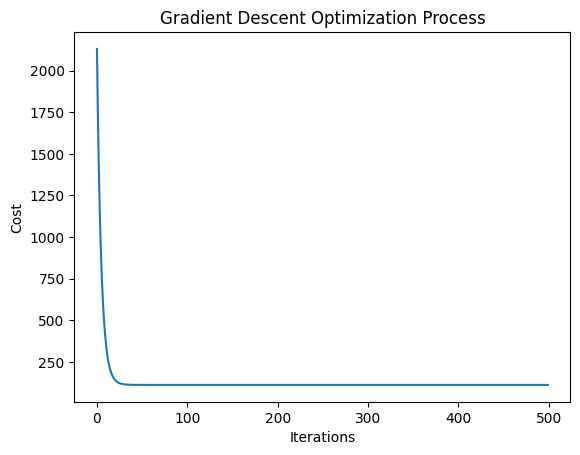

In [23]:
plt.plot(model.cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Optimization Process")
plt.show()